# Notebook-34 AR on the S=7 sweep — seed 42, part a of 2 (S7_k02, S7_k023, S7_k0234)

**Model `ar_slotpos_digithead_target`** (notebook 34). It is the original Transformer AR (same sequence with
delimiters, segment embeddings, teacher forcing, token-by-token decoding) with three changes:
1. **no pos(t)**: op tokens get an op-slot embedding; grid tokens only (row, col);
2. **target coordinates**: every output-part position carries the (row, col) of the cell it PREDICTS
   (`<OUTPUT>` → (0,0), answer of cell j−1 → cell j);
3. **10-way digit head**: loss on the 36 answer digits only (no EOS target), 36 decoding steps.

On S7_k02345 (notebook 34) it reached singletons 1.00, k=6 0.9996, k=7 0.985 — the same level as query AR.

**Setup.** Same as notebooks 23 / 29: S=7 with identity fillers, 20,000 updates, sampled evaluation of the LAST
checkpoint on the same test records, seed 42. S7_k02345 is already done (notebook 34).

**This notebook = part a** (S7_k02, S7_k023, S7_k0234). The other half is notebook 36b; run both at the same time.
The last cell (rerun after both finish) plots this model against the original Transformer AR, query AR and the
causal encoder on all six training supports. **Send back `AR34_vs_QueryAR_vs_Encoder_seed42_Review.ipynb`.**


In [1]:
# --- 2. Bootstrap: locate or clone the PRIVATE repository (credentials are never printed or stored) ---
import base64, importlib.util, os, pathlib, subprocess, sys

REPO_URL = "https://github.com/zhexuandliu/Decompositionality.git"
REPO_BRANCH = "main"
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ

def _find_repo():
    candidates = [pathlib.Path("/content/Decompositionality"), pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
    for p in candidates:
        if (p / "src" / "decompositionality").is_dir():
            return p.resolve()
    return None

REPO_DIR = _find_repo()
if REPO_DIR is None:
    token = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            token = userdata.get("GITHUB_TOKEN")
        except Exception:
            token = None
    if not token:
        import getpass
        token = getpass.getpass("GitHub token with read access to the private repo (input hidden): ")
    # Pass the credential through environment-scoped git config (not the URL, not the command line,
    # not persisted in .git/config).
    _hdr = "AUTHORIZATION: basic " + base64.b64encode(f"x-access-token:{token}".encode()).decode()
    _env = dict(os.environ, GIT_TERMINAL_PROMPT="0", GIT_CONFIG_COUNT="1",
                GIT_CONFIG_KEY_0="http.https://github.com/.extraheader", GIT_CONFIG_VALUE_0=_hdr)
    REPO_DIR = pathlib.Path("/content/Decompositionality" if IN_COLAB else "Decompositionality").resolve()
    _r = subprocess.run(["git", "clone", "--depth", "1", "--branch", REPO_BRANCH, REPO_URL, str(REPO_DIR)],
                        env=_env, capture_output=True, text=True)
    del token, _hdr, _env
    if _r.returncode != 0:
        raise RuntimeError("git clone failed (check the GITHUB_TOKEN secret / repo access):\n" + _r.stderr[-2000:])

if str(REPO_DIR / "src") not in sys.path:
    sys.path.insert(0, str(REPO_DIR / "src"))
for _mod in ("numpy", "pandas", "matplotlib", "torch"):
    if importlib.util.find_spec(_mod) is None:  # Colab already ships these; never reinstall torch/CUDA here
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", _mod], check=True)
REPO_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"], capture_output=True, text=True).stdout.strip()
print("Repository:", REPO_DIR, "| commit:", REPO_COMMIT or "unknown")


Repository: /content/Decompositionality | commit: 36ae572adb47f3bcf37ec5a8786478ebd87aeb88


In [2]:
# --- CONFIGURATION -------------------------------------------------------------------------------------------------
MODE = os.environ.get("DECOMP_MODE", "full")
SEED = 42
RUN_CONDITIONS = ['S7_k02', 'S7_k023', 'S7_k0234']
RUN_MODELS = ["ar_slotpos_digithead_target"]
STEPS = 20000
SUBDIR = "S7_support_sweep_20k_v1"                # same folder as notebooks 23 / 27 (model subfolders differ)
EVAL_PLAN = {"n_single_grids": 1000, "n_seen_per_k": 5000, "n_long_per_k": 20000}
USE_DRIVE = IN_COLAB
RESULTS_ROOT = os.environ.get("DECOMP_RESULTS_ROOT") or (
    "/content/drive/MyDrive/decompositionality_results" if USE_DRIVE else str(REPO_DIR / "results"))
DEVICE = os.environ.get("DECOMP_DEVICE", "auto")
# -----------------------------------------------------------------------------------------------------------------
if USE_DRIVE and IN_COLAB and RESULTS_ROOT.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
import pandas as pd
from IPython.display import display
pd.set_option("display.max_rows", 500); pd.set_option("display.max_columns", 60); pd.set_option("display.width", 250)
from decompositionality import longk as LK, longk_exp as LX
print("results ->", LX.family_root(RESULTS_ROOT, MODE, SUBDIR))


Mounted at /content/drive
results -> /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1


In [3]:
# --- Train (20,000 updates) + sampled LAST-checkpoint evaluation (resumable) ---------------------------------------
status = LX.run_queue(RESULTS_ROOT, MODE, SEED, RUN_CONDITIONS, RUN_MODELS, repo_dir=str(REPO_DIR), device=DEVICE,
                      subdir=SUBDIR, steps=STEPS if MODE == "full" else None, sampled_plan=EVAL_PLAN)
display(status)


[S7_k02] S=7 train k=[0, 2] | val 600 | manifests bdf24c327a65

=== S7_k02 / ar_slotpos_digithead_target ===
  microbatch probe: 256 fits
[ar_slotpos_digithead_target] 10,670,218 params | device NVIDIA RTX PRO 6000 Blackwell Server Edition | dtype bf16 | microbatch 256 x accumulation 1 = 256
  [val @ 250] cell CE 0.8464 (best) | subset(64) exact 0.547 cell 0.659
  [val @ 500] cell CE 0.0587 (best) | subset(64) exact 0.812 cell 0.977
  step 650/20000 loss 0.0035 lr 3.00e-04 | 31.75 steps/s, 8128 ex/s | ETA 10.2 min
  [val @ 750] cell CE 0.0039 (best) | subset(64) exact 0.984 cell 0.999
  [val @ 1000] cell CE 0.0006 (best) | subset(64) exact 1.000 cell 1.000
  [val @ 1250] cell CE 0.0009 | subset(64) exact 1.000 cell 1.000
  step 1275/20000 loss 0.0009 lr 2.98e-04 | 30.58 steps/s, 7828 ex/s | ETA 10.2 min
  [val @ 1500] cell CE 0.0008 | subset(64) exact 1.000 cell 1.000
  [val @ 1750] cell CE 0.0012 | subset(64) exact 0.984 cell 1.000
  step 1925/20000 loss 0.0001 lr 2.95e-04 | 30.96 ste

,condition,model,trained,evaluated_last,records,best_step (reference),complete
0,S7_k02,ar_slotpos_digithead_target,True,True,127000,9250,True
1,S7_k023,ar_slotpos_digithead_target,True,True,112000,9250,True
2,S7_k0234,ar_slotpos_digithead_target,True,True,97000,20000,True


# S=7 support sweep — 1 seeds [42] (LAST checkpoint, 20,000 updates)
Training seed varies the initialization and the training stream; the held-out grids, validation set and sampled test records are identical for every seed.


### Availability by seed (first 20 of 24 rows; full table in CSV export)


seed,condition,model,42
0,S7_k02,ar_slotpos_digithead_target,available
1,S7_k02,causal_encoder,available
2,S7_k02,query_ar,available
3,S7_k02,transformer_ar,available
4,S7_k023,ar_slotpos_digithead_target,available
5,S7_k023,causal_encoder,available
6,S7_k023,query_ar,available
7,S7_k023,transformer_ar,available
8,S7_k0234,ar_slotpos_digithead_target,available
9,S7_k0234,causal_encoder,available



### Exact accuracy by condition, model and k: mean ± std over seeds, with each seed


,condition,max_train_k,model,k,role,mean,std,min,max,n_seeds,seed 42
0,S7_k02,2,ar_slotpos_digithead_target,0,trained,1.0000,NaN,1.0000,1.0000,1,1.0000
1,S7_k02,2,ar_slotpos_digithead_target,1,singleton,0.0000,NaN,0.0000,0.0000,1,0.0000
2,S7_k02,2,ar_slotpos_digithead_target,2,trained,1.0000,NaN,1.0000,1.0000,1,1.0000
3,S7_k02,2,ar_slotpos_digithead_target,3,+1 step,0.0000,NaN,0.0000,0.0000,1,0.0000
4,S7_k02,2,ar_slotpos_digithead_target,4,+2 step,0.1291,NaN,0.1291,0.1291,1,0.1291
5,S7_k02,2,ar_slotpos_digithead_target,5,+3 step,0.0000,NaN,0.0000,0.0000,1,0.0000
6,S7_k02,2,ar_slotpos_digithead_target,6,+4 step,0.0652,NaN,0.0652,0.0652,1,0.0652
7,S7_k02,2,ar_slotpos_digithead_target,7,+5 step,0.0000,NaN,0.0000,0.0000,1,0.0000
8,S7_k02,2,causal_encoder,0,trained,1.0000,NaN,1.0000,1.0000,1,1.0000
9,S7_k02,2,causal_encoder,1,singleton,0.0000,NaN,0.0000,0.0000,1,0.0000



### Accuracy vs test k for every training support (mean, min–max band, individual seeds)


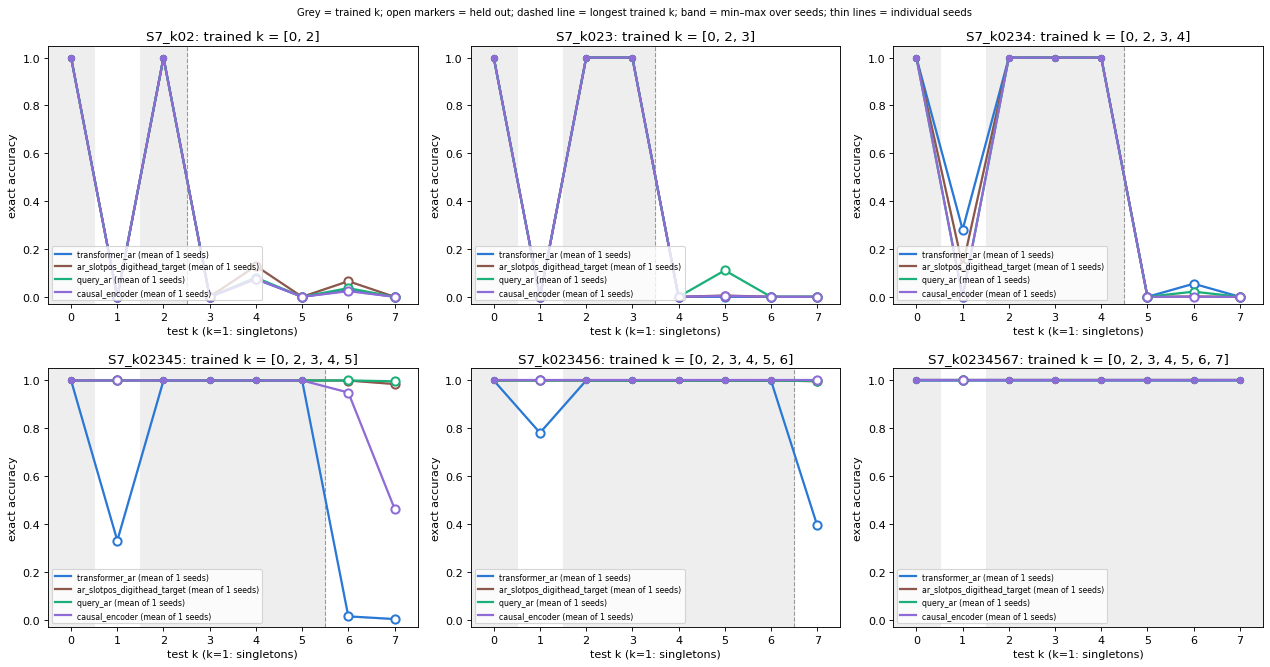


### Singleton / +1 step / +2 step accuracy vs longest trained k


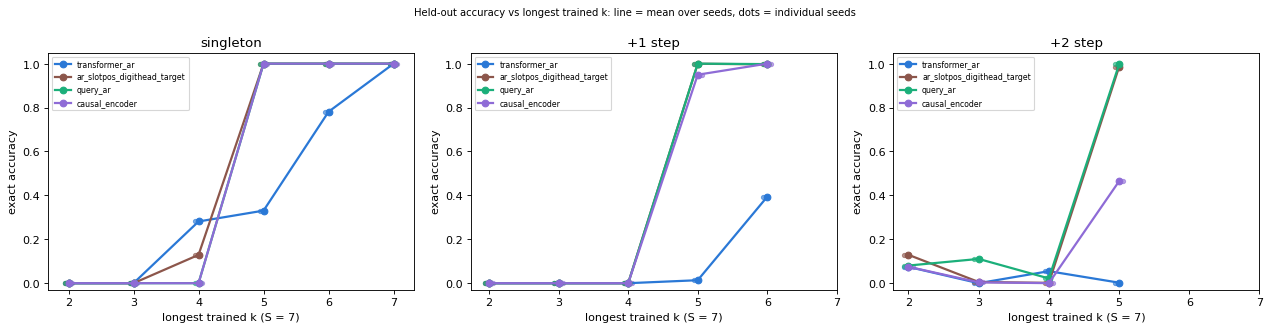

REVIEW FILE: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/ar34_seed42/AR34_vs_QueryAR_vs_Encoder_seed42_Review.ipynb
Held-out accuracy (seed 42):


model                  transformer_ar  ar_slotpos_digithead_target  query_ar  causal_encoder
condition   role                                                                            
S7_k02      singleton          0.0000                       0.0000    0.0000          0.0000
            +1 step            0.0000                       0.0000    0.0000          0.0000
            +2 step            0.0742                       0.1291    0.0804          0.0748
            +3 step            0.0000                       0.0000    0.0000          0.0000
            +4 step            0.0272                       0.0652    0.0363          0.0237
            +5 step            0.0000                       0.0000    0.0000          0.0000
S7_k023     singleton          0.0000                       0.0000    0.0000          0.0000
            +1 step            0.0000                       0.0000    0.0000          0.0000
            +2 step            0.0000                       0.0054    0.1106          0.0038
            +3 step            0.0000                       0.0000    0.0000          0.0000
            +4 step            0.0000                       0.0000    0.0000          0.0000
S7_k0234    singleton          0.2811                       0.1290    0.0002          0.0000
            +1 step            0.0000                       0.0000    0.0000          0.0000
            +2 step            0.0547                       0.0015    0.0216          0.0002
            +3 step            0.0000                       0.0000    0.0000          0.0000
S7_k02345   singleton          0.3305                       1.0000    1.0000          1.0000
            +1 step            0.0136                       0.9996    1.0000          0.9495
            +2 step            0.0024                       0.9848    0.9964          0.4642
S7_k023456  singleton          0.7810                       1.0000    1.0000          1.0000
            +1 step            0.3938                       0.9966    0.9979          1.0000
S7_k0234567 singleton          0.9997                       1.0000    1.0000          1.0000

REVIEW FILE TO SEND BACK: /content/drive/MyDrive/decompositionality_results/S7_support_sweep_20k_v1/report/ar34_seed42/AR34_vs_QueryAR_vs_Encoder_seed42_Review.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# --- Comparison on the whole S=7 sweep, seed 42 (rerun after both halves finish) -------------------------------------
MODELS_CMP = ["transformer_ar", "ar_slotpos_digithead_target", "query_ar", "causal_encoder"]
rp = LX.multiseed_report(RESULTS_ROOT, MODE, [42], LK.S7_SWEEP, SUBDIR, models=MODELS_CMP,
                         out_name="ar34_seed42", review_name="AR34_vs_QueryAR_vs_Encoder_seed42_Review.ipynb")
df = LX.per_k_accuracy(RESULTS_ROOT, MODE, [42], LK.S7_SWEEP, SUBDIR, MODELS_CMP)
ok = df[df.status == "available"]
summary = ok[ok.role != "trained"].pivot_table(index=["condition", "role"], columns="model", values="exact_acc", sort=False)
print("Held-out accuracy (seed 42):")
display(summary[[m for m in MODELS_CMP if m in summary.columns]].round(4))
print("REVIEW FILE TO SEND BACK:", rp)
if IN_COLAB and rp:
    from google.colab import files
    files.download(str(rp))
